Problem Statement: To understand the retail data and determine the effect of the suppliers and their sales

- Dataset Source - https://catalog.data.gov/dataset/warehouse-and-retail-sales


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")


In [2]:
df=pd.read_csv('data/Warehouse_and_Retail_Sales.csv')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307645 entries, 0 to 307644
Data columns (total 9 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   YEAR              307645 non-null  int64  
 1   MONTH             307645 non-null  int64  
 2   SUPPLIER          307478 non-null  object 
 3   ITEM CODE         307645 non-null  object 
 4   ITEM DESCRIPTION  307645 non-null  object 
 5   ITEM TYPE         307644 non-null  object 
 6   RETAIL SALES      307642 non-null  float64
 7   RETAIL TRANSFERS  307645 non-null  float64
 8   WAREHOUSE SALES   307645 non-null  float64
dtypes: float64(3), int64(2), object(4)
memory usage: 21.1+ MB


In [3]:
df.head()

,YEAR,MONTH,SUPPLIER,ITEM CODE,ITEM DESCRIPTION,ITEM TYPE,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
0,2020,1,REPUBLIC NATIONAL DISTRIBUTING CO,100009,BOOTLEG RED - 750ML,WINE,0.00,0.0,2.0
1,2020,1,PWSWN INC,100024,MOMENT DE PLAISIR - 750ML,WINE,0.00,1.0,4.0
2,2020,1,RELIABLE CHURCHILL LLLP,1001,S SMITH ORGANIC PEAR CIDER - 18.7OZ,BEER,0.00,0.0,1.0
3,2020,1,LANTERNA DISTRIBUTORS INC,100145,SCHLINK HAUS KABINETT - 750ML,WINE,0.00,0.0,1.0
4,2020,1,DIONYSOS IMPORTS INC,100293,SANTORINI GAVALA WHITE - 750ML,WINE,0.82,0.0,0.0


In [4]:
df.columns

Index(['YEAR', 'MONTH', 'SUPPLIER', 'ITEM CODE', 'ITEM DESCRIPTION',
       'ITEM TYPE', 'RETAIL SALES', 'RETAIL TRANSFERS', 'WAREHOUSE SALES'],
      dtype='object')

Performing Checks

In [6]:
#duplicates ?
df.duplicated().sum()

0

In [7]:
#unique values
df.nunique()

YEAR                    4
MONTH                  12
SUPPLIER              396
ITEM CODE           34056
ITEM DESCRIPTION    34822
ITEM TYPE               8
RETAIL SALES        10674
RETAIL TRANSFERS     2504
WAREHOUSE SALES      4895
dtype: int64

In [9]:
#statistics
df.describe()

,YEAR,MONTH,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
count,307645.000000,307645.000000,307642.000000,307645.000000,307645.000000
mean,2018.438525,6.423862,7.024071,6.936465,25.294597
std,1.083061,3.461812,30.986238,30.237195,249.916798
min,2017.000000,1.000000,-6.490000,-38.490000,-7800.000000
25%,2017.000000,3.000000,0.000000,0.000000,0.000000
50%,2019.000000,7.000000,0.320000,0.000000,1.000000
75%,2019.000000,9.000000,3.267500,3.000000,5.000000
max,2020.000000,12.000000,2739.000000,1990.830000,18317.000000


In [12]:
#Exploring Categorical data

print("Categories in 'ITEM TYPE' variable:     ",end=" " )
print(df['ITEM TYPE'].unique())


Categories in 'ITEM TYPE' variable:      ['WINE' 'BEER' 'LIQUOR' 'STR_SUPPLIES' 'KEGS' 'REF' 'DUNNAGE'
 'NON-ALCOHOL' nan]


 Understand Date Coverage

In [13]:
print("Years present:")
print(sorted(df['YEAR'].unique()))

print("\nMonths present:")
print(sorted(df['MONTH'].unique()))

Years present:
[2017, 2018, 2019, 2020]

Months present:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [15]:
# Year and Month Combinations

date_coverage = (
    df.groupby(['YEAR', 'MONTH'])
      .size()
      .reset_index(name='Records')
      .sort_values(['YEAR','MONTH'])
)

display(date_coverage)

,YEAR,MONTH,Records
0,2017,6,13628
1,2017,7,13022
2,2017,8,13590
3,2017,9,13386
4,2017,10,13626
5,2017,11,14532
6,2017,12,14500
7,2018,1,13345
8,2018,2,13100
9,2019,1,12392


In [16]:
all_periods = pd.MultiIndex.from_product(
    [sorted(df['YEAR'].unique()),
     range(1,13)],
    names=['YEAR','MONTH']
)

existing_periods = pd.MultiIndex.from_frame(
    df[['YEAR','MONTH']].drop_duplicates()
)

missing_periods = all_periods.difference(existing_periods)

print("Missing Year-Month combinations:")
print(list(missing_periods))

Missing Year-Month combinations:
[(2017, 1), (2017, 2), (2017, 3), (2017, 4), (2017, 5), (2018, 3), (2018, 4), (2018, 5), (2018, 6), (2018, 7), (2018, 8), (2018, 9), (2018, 10), (2018, 11), (2018, 12), (2019, 12), (2020, 2), (2020, 4), (2020, 5), (2020, 6), (2020, 8), (2020, 10), (2020, 11), (2020, 12)]


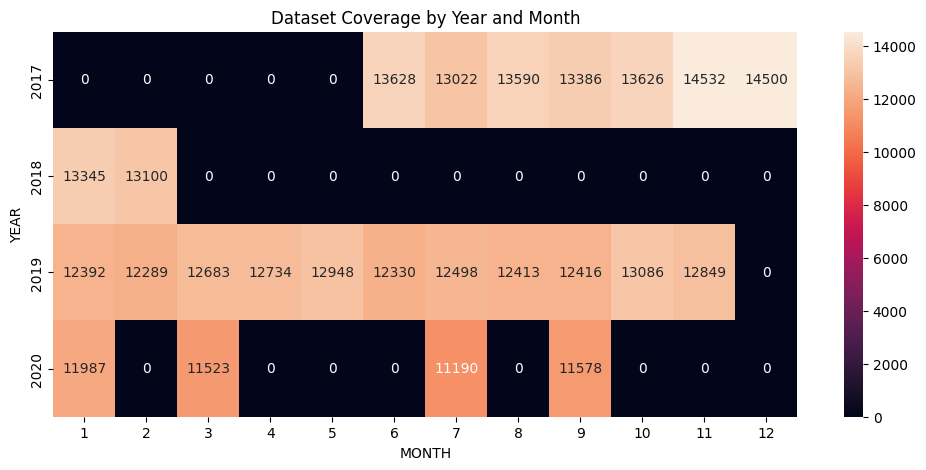

In [17]:
coverage = (
    df.groupby(['YEAR','MONTH'])
      .size()
      .unstack(fill_value=0)
)

plt.figure(figsize=(12,5))
sns.heatmap(coverage, annot=True, fmt='g')
plt.title("Dataset Coverage by Year and Month")
plt.show()

Null Analysis

In [18]:
nulls = pd.DataFrame({
    'Null Count': df.isnull().sum(),
    'Null %': round(df.isnull().mean()*100,2)
})

nulls.sort_values('Null Count', ascending=False)

,Null Count,Null %
SUPPLIER,167,0.05
RETAIL SALES,3,0.00
ITEM TYPE,1,0.00
YEAR,0,0.00
MONTH,0,0.00
ITEM CODE,0,0.00
ITEM DESCRIPTION,0,0.00
RETAIL TRANSFERS,0,0.00
WAREHOUSE SALES,0,0.00


In [19]:
supplier_nulls = df['SUPPLIER'].isnull().sum()

print("Supplier Nulls:", supplier_nulls)

Supplier Nulls: 167


In [20]:
default_rows = df[
    df['SUPPLIER'].astype(str)
    .str.contains('default', case=False, na=False)
]

print("Default Rows:", len(default_rows))

Default Rows: 266


Item Type Analysis

In [21]:
item_type_counts = df['ITEM TYPE'].value_counts(dropna=False)

display(item_type_counts)

ITEM TYPE
WINE            187640
LIQUOR           64910
BEER             42413
KEGS             10146
NON-ALCOHOL       1908
STR_SUPPLIES       405
REF                127
DUNNAGE             95
NaN                  1
Name: count, dtype: int64

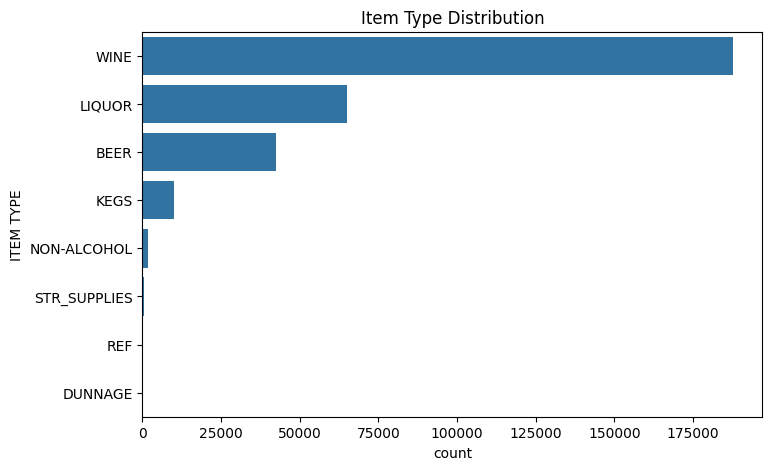

In [45]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    y='ITEM TYPE',
    order=df['ITEM TYPE'].value_counts().index
)

plt.title("Item Type Distribution")
plt.show()

In [23]:
item_sales = (
    df.groupby('ITEM TYPE')['RETAIL SALES']
      .sum()
      .sort_values(ascending=False)
)

display(item_sales)

ITEM TYPE
LIQUOR          802691.43
WINE            746498.59
BEER            574220.53
NON-ALCOHOL      34084.31
STR_SUPPLIES      2740.88
REF                663.63
DUNNAGE              0.00
KEGS                 0.00
Name: RETAIL SALES, dtype: float64

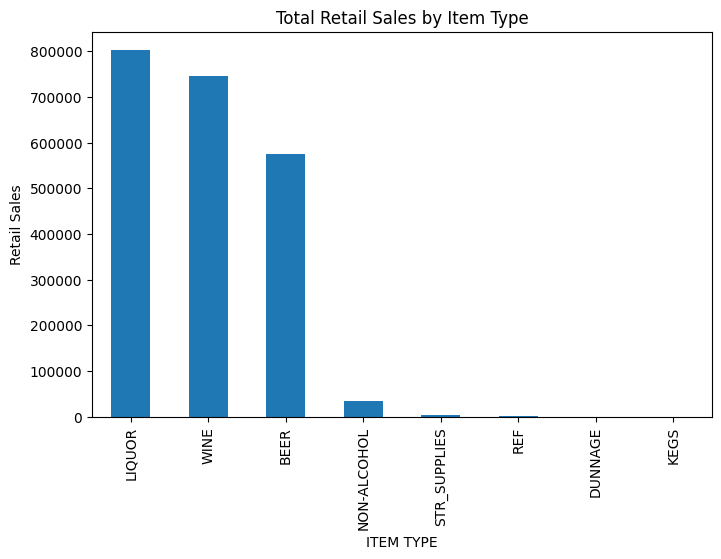

In [44]:
plt.figure(figsize=(8,5))

item_sales.plot(kind='bar')

plt.title("Total Retail Sales by Item Type")
plt.ylabel("Retail Sales")
plt.show()

In [25]:
df.groupby('ITEM TYPE')['RETAIL SALES'].agg(
    ['count','sum','mean']
).sort_values('sum', ascending=False)

,count,sum,mean
ITEM TYPE,,,
LIQUOR,64910,802691.43,12.366221
WINE,187640,746498.59,3.978355
BEER,42413,574220.53,13.538786
NON-ALCOHOL,1905,34084.31,17.892026
STR_SUPPLIES,405,2740.88,6.767605
REF,127,663.63,5.225433
DUNNAGE,95,0.00,0.000000
KEGS,10146,0.00,0.000000


Supplier Analysis

In [26]:
top_suppliers = (
    df.groupby('SUPPLIER')['RETAIL SALES']
      .sum()
      .sort_values(ascending=False)
      .head(20)
)

display(top_suppliers)

SUPPLIER
E & J GALLO WINERY                        166170.53
DIAGEO NORTH AMERICA INC                  145343.20
CONSTELLATION BRANDS                      131664.79
ANHEUSER BUSCH INC                        109960.82
JIM BEAM BRANDS CO                         96164.04
MILLER BREWING COMPANY                     87156.44
CROWN IMPORTS                              84437.66
SAZERAC CO                                 70414.62
BACARDI USA INC                            66610.23
THE WINE GROUP                             64270.04
PERNOD RICARD USA LLC                      57788.88
HEINEKEN USA                               56139.91
HEAVEN HILL DISTILLERIES INC               54245.36
BROWN-FORMAN BEVERAGES WORLDWIDE           50889.69
FIFTH GENERATION INC                       42628.73
BOSTON BEER CORPORATION                    40129.13
DELICATO FAMILY VINEYARDS                  37781.29
DEUTSCH FAMILY WINE & SPIRITS              36551.71
TREASURY WINE ESTATES AMERICAS COMPANY     35989.46
PRO

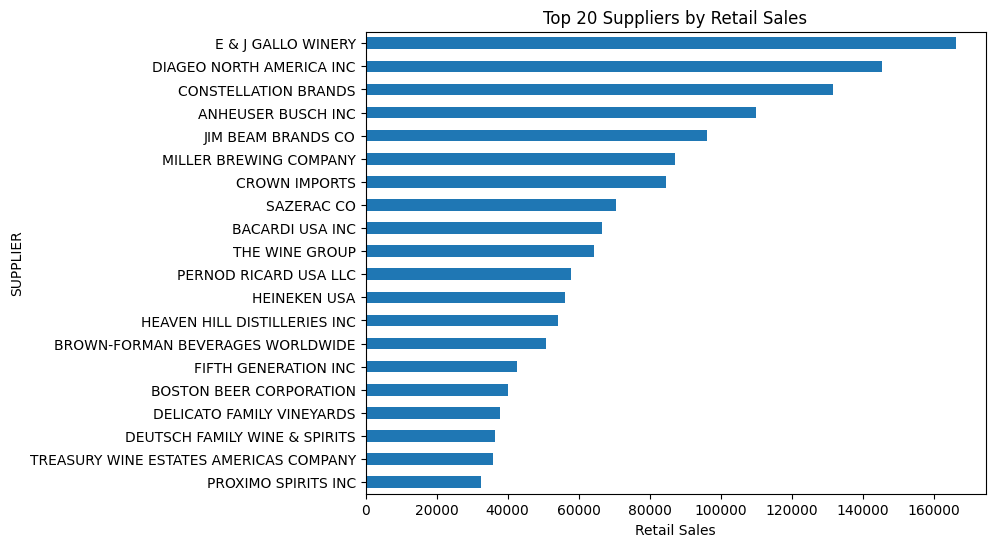

In [40]:
plt.figure(figsize=(8,6))

top_suppliers.sort_values().plot(kind='barh')

plt.title("Top 20 Suppliers by Retail Sales")
plt.xlabel("Retail Sales")
plt.show()

In [28]:
supplier_avg = (
    df.groupby('SUPPLIER')['RETAIL SALES']
      .mean()
      .sort_values(ascending=False)
      .head(20)
)

display(supplier_avg)

SUPPLIER
FIFTH GENERATION INC                302.331418
CROWN IMPORTS                        66.854838
YUENGLING BREWERY                    50.169281
CHARLES JACQUIN ET CIE INC           47.008750
HEINEKEN USA                         43.996795
SINGHA NORTH AMERICA INC             30.294167
MILLER BREWING COMPANY               26.916751
DELICATO FAMILY VINEYARDS            25.913093
MARK ANTHONY BRANDS INC              25.623625
BOSTON BEER CORPORATION              24.786368
EXCELSIOR WINE COMPANY LLC           24.334849
CITIZENS BREWING LLC                 23.894828
PALM BAY IMPORTS                     23.557232
FLYING DOG BREWERY LLLP              21.928910
JACKSON FAMILY ENTERPRISES INC       21.084677
HEAVEN HILL DISTILLERIES INC         20.286223
BROWN-FORMAN BEVERAGES WORLDWIDE     20.170309
BACARDI USA INC                      19.777384
CONSTELLATION BRANDS                 19.698502
PARALLEL WORLD BREWING COMPANY       19.642222
Name: RETAIL SALES, dtype: float64

Retail Sales Distribution

In [29]:
cols = [
    'RETAIL SALES',
    'RETAIL TRANSFERS',
    'WAREHOUSE SALES'
]

df[cols].describe()

,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
count,307642.000000,307645.000000,307645.000000
mean,7.024071,6.936465,25.294597
std,30.986238,30.237195,249.916798
min,-6.490000,-38.490000,-7800.000000
25%,0.000000,0.000000,0.000000
50%,0.320000,0.000000,1.000000
75%,3.267500,3.000000,5.000000
max,2739.000000,1990.830000,18317.000000


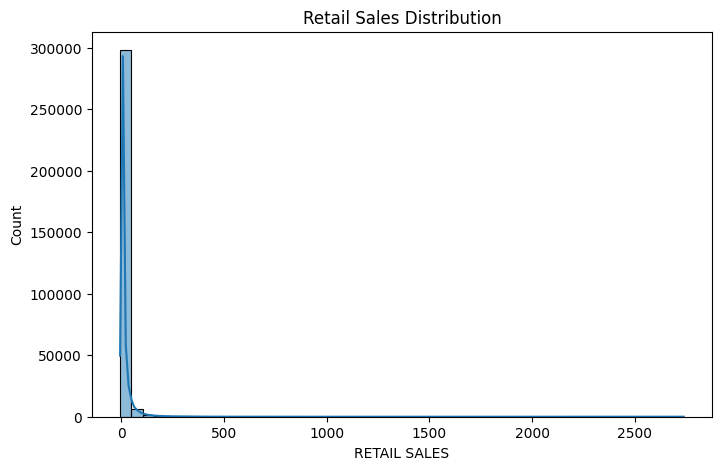

In [41]:
plt.figure(figsize=(8,5))

sns.histplot(
    df['RETAIL SALES'],
    bins=50,
    kde=True
)

plt.title("Retail Sales Distribution")
plt.show()

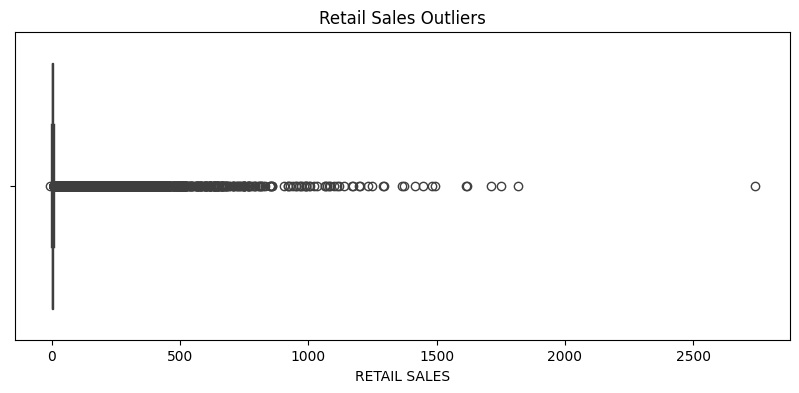

In [32]:
plt.figure(figsize=(10,4))

sns.boxplot(
    x=df['RETAIL SALES']
)

plt.title("Retail Sales Outliers")
plt.show()

In [ ]:
# Zero sales pct
zero_pct = (
    (df['RETAIL SALES'] == 0).mean()*100
)

print(f"Percentage of zero sales: {zero_pct:.2f}%")

Percentage of zero sales: 39.56%


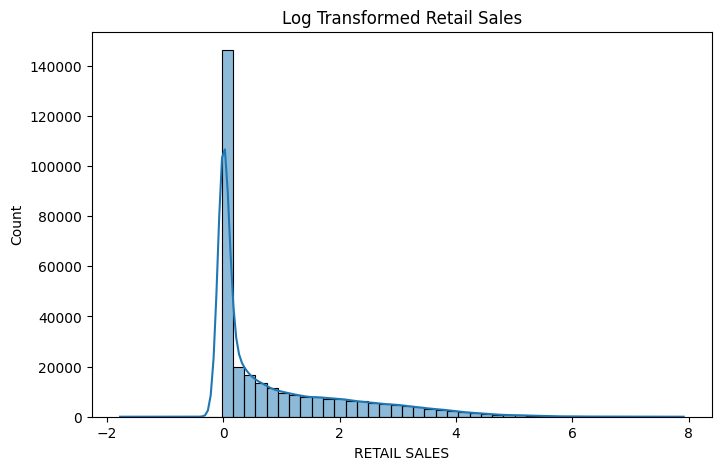

In [42]:
# Log Distribution
plt.figure(figsize=(8,5))

sns.histplot(
    np.log1p(df['RETAIL SALES']),
    bins=50,
    kde=True
)

plt.title("Log Transformed Retail Sales")
plt.show()

In [36]:
# Retail Transfers vs Warehouse Sales
df[['RETAIL SALES',
    'RETAIL TRANSFERS',
    'WAREHOUSE SALES']].corr()


,RETAIL SALES,RETAIL TRANSFERS,WAREHOUSE SALES
RETAIL SALES,1.000000,0.960054,0.490472
RETAIL TRANSFERS,0.960054,1.000000,0.492093
WAREHOUSE SALES,0.490472,0.492093,1.000000


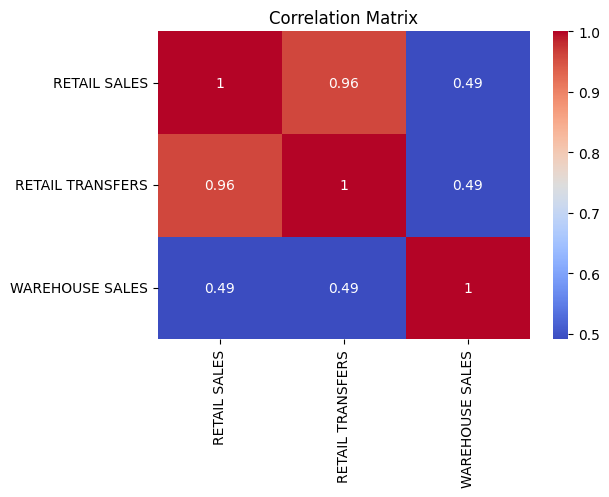

In [37]:
plt.figure(figsize=(6,4))

sns.heatmap(
    df[['RETAIL SALES',
        'RETAIL TRANSFERS',
        'WAREHOUSE SALES']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Matrix")
plt.show()

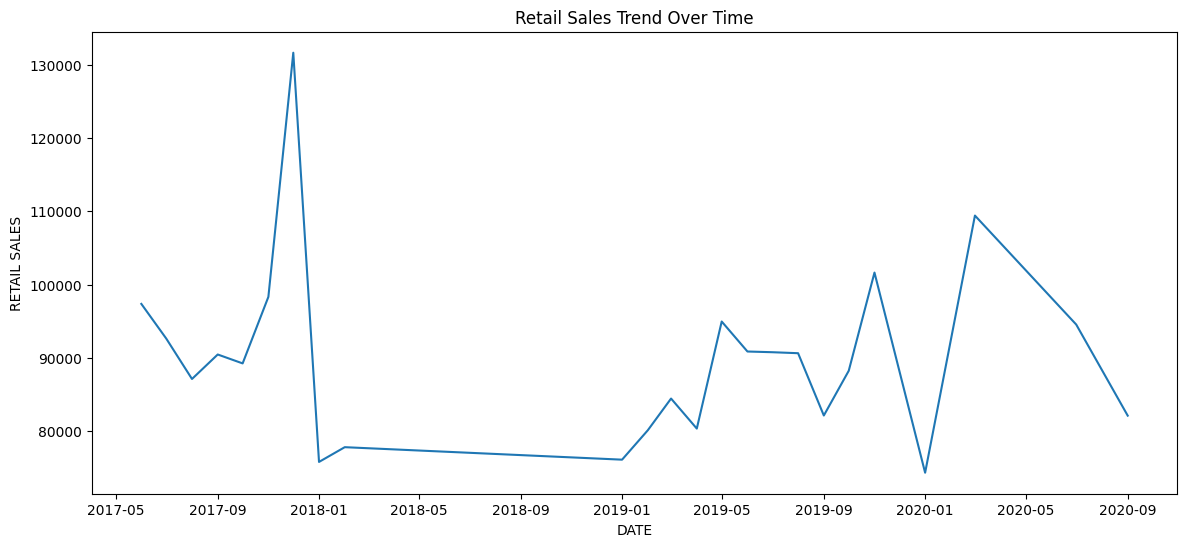

In [ ]:
# Sales Trend over time

monthly_sales = (
    df.groupby(['YEAR','MONTH'])
      ['RETAIL SALES']
      .sum()
      .reset_index()
)

monthly_sales['DATE'] = pd.to_datetime(
    monthly_sales['YEAR'].astype(str)
    + '-'
    + monthly_sales['MONTH'].astype(str)
)

plt.figure(figsize=(14,6))
sns.lineplot(
    data=monthly_sales,
    x='DATE',
    y='RETAIL SALES'
)

plt.title("Retail Sales Trend Over Time")
plt.show()

In [39]:
# Top 10 Items * Suppliers

top_supplier_item = (
    df.groupby(['SUPPLIER','ITEM TYPE'])
      ['RETAIL SALES']
      .sum()
      .reset_index()
      .sort_values(
          'RETAIL SALES',
          ascending=False
      )
      .head(20)
)

display(top_supplier_item)

,SUPPLIER,ITEM TYPE,RETAIL SALES
181,E & J GALLO WINERY,WINE,134199.27
142,DIAGEO NORTH AMERICA INC,LIQUOR,118800.90
120,CONSTELLATION BRANDS,WINE,108269.49
25,ANHEUSER BUSCH INC,BEER,105052.60
275,JIM BEAM BRANDS CO,LIQUOR,95899.38
341,MILLER BREWING COMPANY,BEER,86948.24
126,CROWN IMPORTS,BEER,84437.66
458,SAZERAC CO,LIQUOR,68829.43
532,THE WINE GROUP,WINE,64270.04
40,BACARDI USA INC,LIQUOR,59502.57
